# Top 10s
Top artists, albums, and songs for a chosen time period.

## Load data
Uses `scrobbles.parquet` from the project folder, or `sample_data/` if it isn't there.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = '.' if os.path.exists('scrobbles.parquet') else 'sample_data'  # falls back to the bundled sample
print(f'data: {DATA_DIR}')

df = pd.read_parquet(f'{DATA_DIR}/scrobbles.parquet')
print(df.shape)
df.dtypes

data: .
(34009, 5)


artist                                  str
album                                   str
track                                   str
uts                                   int64
played_at    datetime64[us, America/Denver]
dtype: object

## Periods and keys
Each period is a window that ends at the latest scrobble; `None` means no cutoff (all time). Albums and songs are identified by artist plus name, since titles repeat across artists.

In [2]:
as_of = df['played_at'].max()

PERIODS = {
    'week': pd.DateOffset(weeks=1),
    'month': pd.DateOffset(months=1),
    '3 months': pd.DateOffset(months=3),
    '6 months': pd.DateOffset(months=6),
    'year': pd.DateOffset(years=1),
    'overall': None,
}

KEYS = {
    'artists': ['artist'],
    'albums': ['artist', 'album'],
    'songs': ['artist', 'track'],
}

## Top n
Filter to the period, count plays per artist, album, or song, and keep the top `n`.

In [3]:
def top_n(df, kind, period='overall', n=10):
    '''Return the n most-played artists, albums, or songs within a period.'''
    offset = PERIODS[period]
    if offset is not None:  # None means overall, so no filtering
        df = df[df['played_at'] > as_of - offset]  # keep rows inside the window
    if kind == 'albums':
        df = df[df['album'] != '']  # blank album means no album info, so skip it
    return (df.groupby(KEYS[kind])
              .size()
              .nlargest(n)
              .reset_index(name='plays'))

In [4]:
top_n(df, 'artists', period='week', n=100)

,artist,plays
0,GZA/Genius,16
1,Mitski,15
2,Phantogram,12
3,Billie Holiday,10
4,Bonobo,10
...,...,...
95,Dr. Dre,1
96,Dreamgirl,1
97,Duke Ellington,1
98,"Earth, Wind & Fire",1


## Bar chart
Horizontal bars, largest on top, with the play count at the end of each bar.

In [5]:
from viz import BAR_COLOR, SURFACE, INK, add_title, save_figure

PERIOD_LABELS = {
    'week': 'past week',
    'month': 'past month',
    '3 months': 'past 3 months',
    '6 months': 'past 6 months',
    'year': 'past year',
    'overall': 'all time',
}

NAME_COLUMN = {'albums': 'album', 'songs': 'track'}

AS_OF_TEXT = f'{as_of:%b} {as_of.day}, {as_of.year}'


def shorten(text, max_chars=42):
    '''Truncate long labels so they don't squeeze the plot.'''
    return text if len(text) <= max_chars else text[:max_chars - 1].rstrip() + '…'


def make_labels(top, kind):
    '''Build one axis label per row: the artist alone, or 'name - artist' for albums and songs.'''
    if kind == 'artists':
        return [shorten(artist) for artist in top['artist']]
    names = top[NAME_COLUMN[kind]]
    return [f'{shorten(name, 30)} - {shorten(artist, 22)}' for name, artist in zip(names, top['artist'])]


def draw_bars(labels, plays, title, subtitle, save_as=None):
    '''Horizontal bars with the largest on top and the value at the end of each bar.'''
    height = 0.42 * len(labels) + 1.3  # inches: one slot per bar plus room for the title

    fig, ax = plt.subplots(figsize=(8, height), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)

    bars = ax.barh(labels, plays, height=0.55, color=BAR_COLOR)
    ax.bar_label(bars, labels=[f'{value:,}' for value in plays],
                 padding=5, fontsize=9, color=INK)

    ax.invert_yaxis()  # largest bar on top
    ax.set_xlim(0, max(plays) * 1.1)  # leave room for the value labels
    ax.xaxis.set_visible(False)  # every bar is labeled, so the axis is redundant
    ax.tick_params(axis='y', length=0, labelsize=10, labelcolor=INK)
    for spine in ax.spines.values():
        spine.set_visible(False)

    add_title(fig, title, subtitle, height)

    fig.tight_layout(rect=(0, 0, 1, 1 - 0.65 / height))
    if save_as:
        save_figure(fig, save_as)
    plt.show()


def plot_top_n(df, kind, period='overall', n=10, save=False):
    '''Bar chart of the top n artists, albums, or songs in a period. save=True writes it to figures/.'''
    top = top_n(df, kind, period, n)
    draw_bars(make_labels(top, kind), top['plays'],
              f'Top {kind}, {PERIOD_LABELS[period]}',
              f'Scrobbles through {AS_OF_TEXT}',
              save_as=f'top_{kind}_{period}'.replace(' ', '_') if save else None)

## Top tags
Tags are cleaned first (see `tags.py`): junk and decade tags are dropped, along with any tag with a weight below 20, and each artist keeps at most 10 tags. Plays are then counted per tag. A play counts once for every tag its artist has, so tag totals overlap.

In [6]:
from tags import clean_tags

raw_tags = pd.read_parquet(f'{DATA_DIR}/artist_tags.parquet')
artist_tags = clean_tags(raw_tags)
untagged = raw_tags['artist'].nunique() - artist_tags['artist'].nunique()
print(f'{len(raw_tags):,} tag rows -> {len(artist_tags):,}; {untagged} artists left with no tags')


def top_tags(df, artist_tags, period='overall', n=10):
    '''Return the n tags with the most plays. A play counts once for every tag its artist carries.'''
    offset = PERIODS[period]
    if offset is not None:
        df = df[df['played_at'] > as_of - offset]
    tags = artist_tags[['artist', 'tag']].drop_duplicates()
    plays = df.merge(tags, on='artist')  # one row per (scrobble, tag)
    counts = plays.groupby('tag').size()
    return counts.nlargest(n).reset_index(name='plays')


def plot_top_tags(df, artist_tags, period='overall', n=10, save=False):
    '''Bar chart of the top n tags in a period. save=True writes it to figures/.'''
    top = top_tags(df, artist_tags, period, n)
    draw_bars(list(top['tag']), top['plays'],
              f'Top tags, {PERIOD_LABELS[period]}',
              f'Plays of artists carrying each tag, through {AS_OF_TEXT}',
              save_as=f'top_tags_{period}'.replace(' ', '_') if save else None)

14,130 tag rows -> 4,974; 1 artists left with no tags


## Tag review
Top tags by overall plays, for finding more tags to add to `STOPLIST` in `tags.py`.

In [7]:
N_TAGS = 40

top_tags(df, artist_tags, 'overall', n=N_TAGS)

,tag,plays
0,indie,10612
1,rock,7984
2,alternative,5953
3,electronic,5481
4,indie pop,5473
5,hip-hop,5271
6,indie rock,4957
7,rap,4365
8,classic rock,4219
9,singer-songwriter,3703


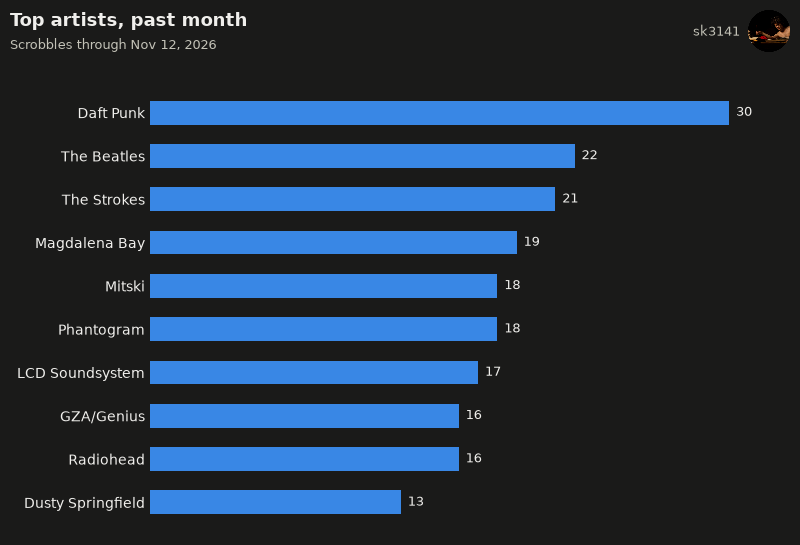

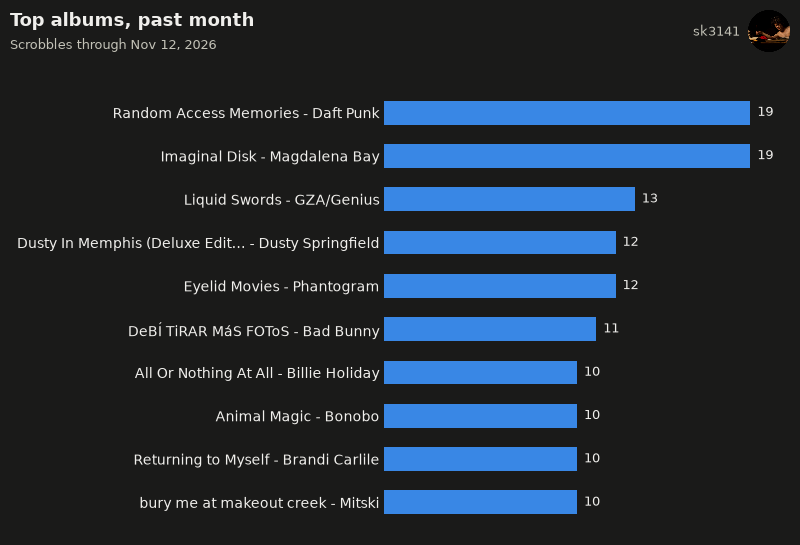

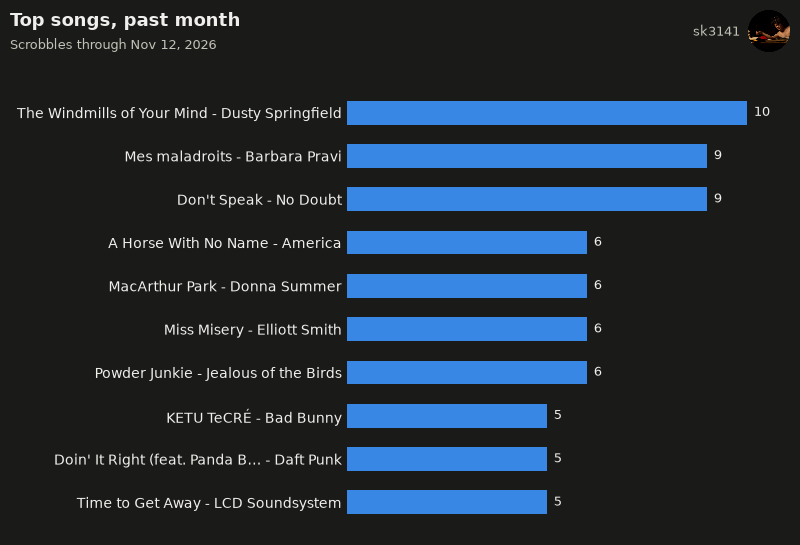

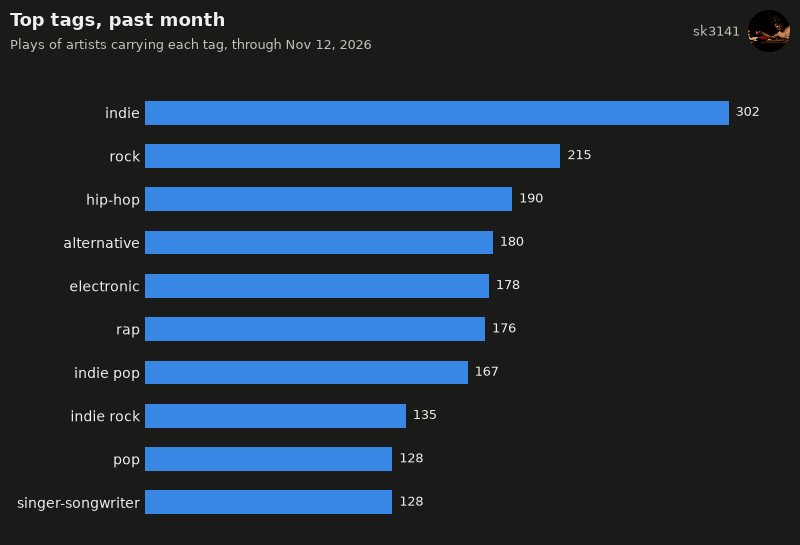

In [8]:
PERIOD = 'month'  # week, month, 3 months, 6 months, year, or overall

for kind in KEYS:
    plot_top_n(df, kind, PERIOD)
plot_top_tags(df, artist_tags, PERIOD)

## Export figures
Save the charts used in the README to `figures/`.

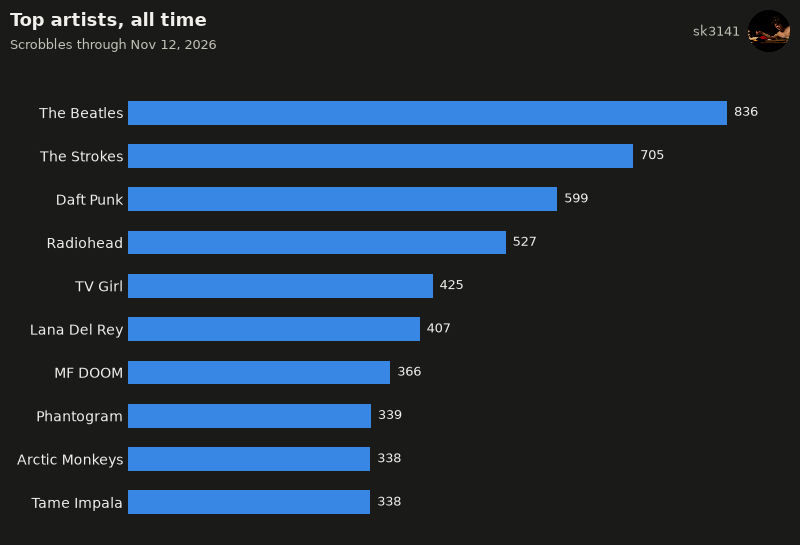

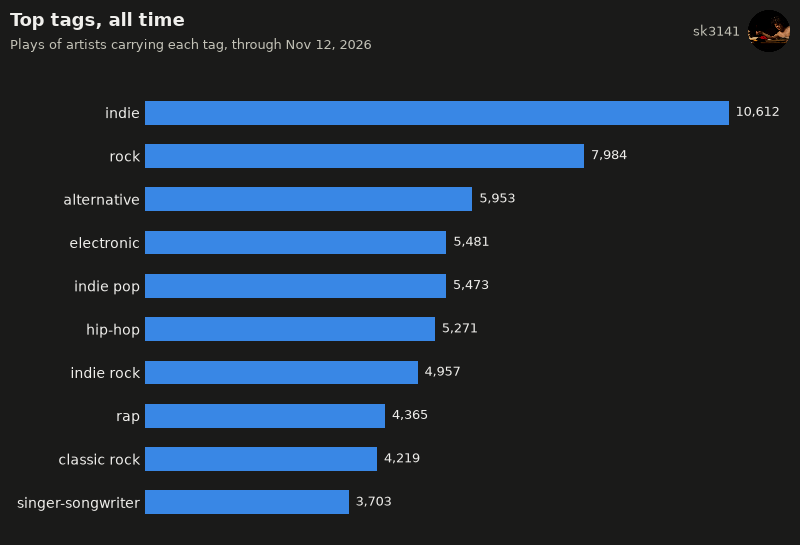

In [9]:
plot_top_n(df, 'artists', 'overall', save=True)
plot_top_tags(df, artist_tags, 'overall', save=True)

In [10]:
print(df['artist'].nunique()) # how many artists?
print(df[['artist', 'track']].drop_duplicates().shape[0]) # how many unique tracks?

1787
8148
